# NexiEmotionNet: Experiments for Lightweight Facial Emotion Recognition on RAF-DB

This notebook contains the NexiEmotionNet implementation (four custom convolution blocks, a simplified CBAM, global average pooling and a fully connected classifier) together with all experiments reported in the paper:

| What | Section |
|---|---|
| Model, loss, optimizer, scheduler, augmentation | 5-8 |
| Ablation study (CNN, CNN+CBAM, CNN+Focal, full model), 5 seeds | 11 |
| Mean ± std, paired t-tests, Wilcoxon tests, component effects | 12 |
| Per-class metrics of NexiEmotionNet | 13 |
| ResNet-18, MobileNetV2, EfficientNet-B0 trained under the identical pipeline | 14 |
| Parameters, FLOPs, GPU/CPU latency, efficiency score, Welch tests | 15 |
| TorchScript export and confusion matrices | 16-17 |
| Reproducibility summary | 18 |

**How to run (local NVIDIA GPU):** obtain RAF-DB from its authors, put `RAF DB Dataset.zip` in the same folder as this notebook (expected layout after extraction: `dataset/DATASET/train/1..7` and `dataset/DATASET/test/1..7`) and run the cells from top to bottom. Every finished run is saved as a JSON file in `NexiEmotionNet_results/runs`, so if the kernel stops you can simply re-run the notebook and completed runs are skipped automatically.

**Important:** use the **same GPU for all runs**. Keep the laptop plugged in, in high-performance mode, with sleep disabled.


## 0. Local Setup (once)

Install a CUDA build of PyTorch first (check the exact command for your driver at pytorch.org), then the other packages. Example for CUDA 12.1:

```
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
pip install scikit-learn scipy pandas matplotlib jupyter
```

Check in a Python shell that `torch.cuda.is_available()` returns `True` before starting.

In [1]:
%pip install scikit-learn scipy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch
import sklearn
import scipy
import pandas
import matplotlib

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not detected")

PyTorch: 2.11.0+cu128
CUDA: True
GPU: NVIDIA GeForce RTX 5060


## 1. Imports and Global Configuration

In [3]:
# ----------------------------------------------------------------------
# Standard library
# ----------------------------------------------------------------------
import os, json, time, random, shutil, zipfile, platform, inspect
from pathlib import Path

# ----------------------------------------------------------------------
# Scientific and deep-learning stack
# ----------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

try:
    from IPython.display import display
except ImportError:                      # fallback when running outside Jupyter
    display = print

# ----------------------------------------------------------------------
# Experiment switches (set to False to skip a block)
# ----------------------------------------------------------------------
RUN_TIMING_PROBE            = False   # set True only to estimate the run time
RUN_ABLATION                = True    # Section 11: 4 ablation groups x seeds
RUN_BASELINES               = True    # Section 14: ResNet-18, MobileNetV2, EfficientNet-B0

# ----------------------------------------------------------------------
# Training configuration
# ----------------------------------------------------------------------
SEEDS          = [0, 1, 2, 3, 4]      # five independent runs
BASELINE_SEEDS = SEEDS                # seeds used for the baseline models
EPOCHS         = 30                   # full training length (the timing probe only trains 1 throw-away epoch)
BATCH_SIZE     = 64
LR             = 1e-3                 # AdamW learning rate == OneCycleLR max_lr
BASELINE_LOSS  = "focal"              # baselines use the same loss as NexiEmotionNet

STRICT_FP32    = True                 # disable TF32 so that all runs use plain FP32
DETERMINISTIC  = True                 # deterministic cuDNN kernels (speed only, not accuracy)

BASELINES = ["resnet18", "mobilenet_v2", "efficientnet_b0"]

# RAF-DB class order (folders 1..7 of the dataset)
CLASS_NAMES = ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Neutral"]
class_names = CLASS_NAMES             # name used in the original notebook

# Latency measurement protocol (Section 15)
LATENCY_WARMUP, LATENCY_ITERS, LATENCY_REPEATS = 50, 200, 5

BASE_DIR = Path.cwd()   # folder of this notebook: dataset zip, results and checkpoints live here
print("Working folder:", BASE_DIR)

Working folder: <project folder>


## 2. Result Storage (Local Folder, Resume-Safe)

In [4]:
# All run results, checkpoints, tables and figures are written to RESULTS_DIR.
# This is a local folder next to the notebook, so finished runs survive a restart of the kernel or the computer.
RESULTS_DIR = BASE_DIR / "NexiEmotionNet_results"

for sub in ["runs", "checkpoints", "tables", "figures"]:
    (RESULTS_DIR / sub).mkdir(parents=True, exist_ok=True)

print("Results will be stored in:", RESULTS_DIR)


Results will be stored in: <project folder>\NexiEmotionNet_results


## 3. Reproducibility: Seeds, Deterministic Settings and Environment Report

In [5]:
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. GPU training cannot start.")

device = torch.device("cuda:0")

torch.cuda.set_device(0)

print("Training device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA version:", torch.version.cuda)

# Numerical settings: strict FP32 and deterministic cuDNN kernels
if STRICT_FP32:
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cuda.matmul.allow_tf32 = False
if DETERMINISTIC:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def set_seed(seed):
    """Fix all random number generators (Python, NumPy, PyTorch CPU and CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def _cpu_name():
    """Return the CPU model name (Windows, Linux or macOS)."""
    try:
        if platform.system() == "Windows":
            import winreg
            with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE,
                                r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as k:
                return winreg.QueryValueEx(k, "ProcessorNameString")[0].strip()
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or "unknown"


def _ram_gb():
    """Return the total system memory in GB (Windows or Linux); None if it cannot be read."""
    try:
        if platform.system() == "Windows":
            import ctypes

            class MEMORYSTATUSEX(ctypes.Structure):
                _fields_ = [("dwLength", ctypes.c_ulong), ("dwMemoryLoad", ctypes.c_ulong),
                            ("ullTotalPhys", ctypes.c_ulonglong), ("ullAvailPhys", ctypes.c_ulonglong),
                            ("ullTotalPageFile", ctypes.c_ulonglong), ("ullAvailPageFile", ctypes.c_ulonglong),
                            ("ullTotalVirtual", ctypes.c_ulonglong), ("ullAvailVirtual", ctypes.c_ulonglong),
                            ("sullAvailExtendedVirtual", ctypes.c_ulonglong)]

            st = MEMORYSTATUSEX()
            st.dwLength = ctypes.sizeof(MEMORYSTATUSEX)
            ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(st))
            return round(st.ullTotalPhys / 1024 ** 3, 1)
        with open("/proc/meminfo") as f:
            for line in f:
                if line.startswith("MemTotal"):
                    return round(int(line.split()[1]) / 1024 / 1024, 1)
    except Exception:
        pass
    return None


def collect_environment():
    """Collect the hardware / software details of the experimental setup."""
    import torchvision
    on_gpu = torch.cuda.is_available()
    return {
        "gpu_name": torch.cuda.get_device_name(0) if on_gpu else "CPU only",
        "gpu_count": torch.cuda.device_count() if on_gpu else 0,
        "gpu_memory_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if on_gpu else None,
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "python": platform.python_version(),
        "os": platform.platform(),
        "cpu_name": _cpu_name(),
        "cpu_count": os.cpu_count(),
        "ram_gb": _ram_gb(),
        "strict_fp32": STRICT_FP32,
        "deterministic_cudnn": DETERMINISTIC,
    }


ENV = collect_environment()
with open(RESULTS_DIR / "environment.json", "w") as f:
    json.dump(ENV, f, indent=2)

display(pd.DataFrame(list(ENV.items()), columns=["Item", "Value"]))
if device.type == "cuda" and "Laptop" in ENV["gpu_name"]:
    print("Laptop GPU detected: keep the charger plugged in, use the high-performance power mode and disable sleep,")
    print("otherwise thermal / power throttling slows the runs and makes the latency measurement unstable.")
if device.type == "cpu":
    print("WARNING: no GPU detected. Switch the runtime to GPU before starting the experiments.")

Training device: cuda:0
GPU: NVIDIA GeForce RTX 5060
CUDA version: 12.8


,Item,Value
0,gpu_name,NVIDIA GeForce RTX 5060
1,gpu_count,1
2,gpu_memory_gb,8.5
3,cuda,12.8
4,cudnn,91900
5,torch,2.11.0+cu128
6,torchvision,0.26.0+cu128
7,python,3.13.7
8,os,Windows-10-10.0.19045-SP0
9,cpu_name,"Intel64 Family 6 Model 151 Stepping 5, Genuine..."


## 4. Extract the RAF-DB Dataset

In [6]:
# Place "RAF DB Dataset.zip" in the same folder as this notebook (it is extracted once).
zip_path = str(BASE_DIR / "RAF DB Dataset.zip")
extract_path = str(BASE_DIR / "dataset")

if not os.path.isdir(os.path.join(extract_path, "DATASET")):
    if not os.path.exists(zip_path):
        raise FileNotFoundError(f"Place 'RAF DB Dataset.zip' next to this notebook: {zip_path}")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

train_dir = os.path.join(extract_path, "DATASET", "train")
test_dir = os.path.join(extract_path, "DATASET", "test")


def count_images(root):
    """Count the images in every class folder of an ImageFolder-style directory."""
    counts = {}
    for cls in sorted(os.listdir(root)):
        p = os.path.join(root, cls)
        if os.path.isdir(p):
            counts[cls] = len([f for f in os.listdir(p) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    return counts


train_counts, test_counts = count_images(train_dir), count_images(test_dir)
overview = pd.DataFrame({"Train": train_counts, "Test": test_counts})
overview.insert(0, "Emotion", CLASS_NAMES[:len(overview)])
overview.loc["Total"] = ["", overview["Train"].sum(), overview["Test"].sum()]
display(overview)

,Emotion,Train,Test
1,Surprise,1290,329
2,Fear,281,74
3,Disgust,717,160
4,Happiness,4772,1185
5,Sadness,1982,478
6,Anger,705,162
7,Neutral,2524,680
Total,,12271,3068


## 5. Data Transforms and Data Loaders

In [7]:
# ----- Transforms -----
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

train_ds = datasets.ImageFolder(train_dir, transform=train_transforms)
test_ds = datasets.ImageFolder(test_dir, transform=test_transforms)

# ImageFolder sorts the folders alphabetically: "1".."7" -> indices 0..6 (RAF-DB label order)
if train_ds.classes != [str(i) for i in range(1, 8)]:
    print("WARNING: unexpected class folders:", train_ds.classes)

# ----- Data loaders -----
# num_workers / pin_memory only speed up data loading; they do not change the model or the maths.
NUM_WORKERS = min(4, os.cpu_count() or 2)
# If DataLoader workers hang or raise errors on Windows, set NUM_WORKERS = 0 (data loading becomes slower).


def make_train_loader(seed, dataset=None):
    """Training loader with a seeded generator so that the data order is reproducible."""
    dataset = train_ds if dataset is None else dataset
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, generator=g,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
                      persistent_workers=(NUM_WORKERS > 0))


def make_eval_loader(dataset):
    """Evaluation loader (no shuffling)."""
    return DataLoader(dataset, batch_size=64, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))


test_loader = make_eval_loader(test_ds)
train_loader = make_train_loader(SEEDS[0])    # used to report steps_per_epoch

print(f"Train images: {len(train_ds)} | Test images: {len(test_ds)} | steps per epoch: {len(train_loader)}")
print("\nAugmentation pipeline (training):")
for t in train_transforms.transforms:
    print("  ", t)
print("\nPreprocessing pipeline (test):")
for t in test_transforms.transforms:
    print("  ", t)

Train images: 12271 | Test images: 3068 | steps per epoch: 192

Augmentation pipeline (training):
   Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
   RandomHorizontalFlip(p=0.5)
   RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
   ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.2, 0.2))
   ToTensor()
   Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])

Preprocessing pipeline (test):
   Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
   ToTensor()
   Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])


## 6. Model Definitions

### 6.1 CBAM Attention Block

In [8]:
class CBAMBlock(nn.Module):
    """Channel attention followed by spatial attention (CBAM)."""

    def __init__(self, ch, reduction=16):
        super().__init__()
        self.ca = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch, ch // reduction, 1),
            nn.ReLU(),
            nn.Conv2d(ch // reduction, ch, 1),
            nn.Sigmoid()
        )
        self.sa = nn.Sequential(
            nn.Conv2d(2, 1, 7, padding=3),
            nn.Sigmoid()
        )

    def forward(self, x):
        ca = self.ca(x)
        x = x * ca
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        sa = self.sa(torch.cat([avg_out, max_out], dim=1))
        return x * sa

### 6.2 Custom Convolution Block (CCB)

In [9]:
class CustomConvBlock(nn.Module):
    """Two 3x3 convolutions (each with BatchNorm + ReLU) followed by optional max-pooling."""

    def __init__(self, in_ch, out_ch, pool=True):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2) if pool else nn.Identity()
        )

    def forward(self, x):
        return self.block(x)

### 6.3 NexiEmotionNet Architecture

The optional `use_cbam` switch (default `True`) is needed for the ablation study. With the default arguments this is the full NexiEmotionNet.

In [10]:
class NexiEmotionNet(nn.Module):
    def __init__(self, num_classes=7, use_cbam=True, cbam_reduction=16):
        super().__init__()
        self.layer1 = CustomConvBlock(3, 32)
        self.layer2 = CustomConvBlock(32, 64)
        self.layer3 = CustomConvBlock(64, 128)
        self.layer4 = CustomConvBlock(128, 256)
        # use_cbam=False replaces the attention block by an identity mapping (ablation only)
        self.cbam = CBAMBlock(256, cbam_reduction) if use_cbam else nn.Identity()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.cbam(x)
        x = self.pool(x).squeeze(-1).squeeze(-1)
        x = self.drop(x)
        return self.fc(x)

### 6.4 Focal Loss and Model / Loss Factories

In [11]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.25):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha

    def forward(self, input, target):
        ce_loss = F.cross_entropy(input, target, reduction='none')
        pt = torch.exp(-ce_loss)
        return (self.alpha * (1 - pt) ** self.gamma * ce_loss).mean()


def build_criterion(name):
    """Return the loss function by name ("focal" or "ce")."""
    if name == "focal":
        return FocalLoss()
    if name == "ce":
        return nn.CrossEntropyLoss()
    raise ValueError(f"Unknown loss: {name}")


def build_model(name, num_classes=7, **kwargs):
    """Return NexiEmotionNet or one of the baseline networks (random initialisation, no pre-training)."""
    if name == "nexiemotionnet":
        return NexiEmotionNet(num_classes=num_classes, **kwargs)
    if name == "resnet18":
        return models.resnet18(weights=None, num_classes=num_classes)
    if name == "mobilenet_v2":
        return models.mobilenet_v2(weights=None, num_classes=num_classes)
    if name == "efficientnet_b0":
        return models.efficientnet_b0(weights=None, num_classes=num_classes)
    raise ValueError(f"Unknown model: {name}")

## 7. Parameter Count and Hyper-Parameter Report

In [12]:
# ----- Parameter count of the actual architecture -----
_probe_model = NexiEmotionNet()
n_params = sum(p.numel() for p in _probe_model.parameters())
print(f"NexiEmotionNet parameters: {n_params:,} ({n_params / 1e6:.3f} M)")

# ----- Layer-wise structure table -----
_rows, _hooks = [], []


def _make_hook(layer_name):
    def hook(module, inputs, output):
        _rows.append({"Layer": layer_name, "Output shape": tuple(output.shape),
                      "Parameters": sum(p.numel() for p in module.parameters())})
    return hook


for _name, _child in _probe_model.named_children():
    _hooks.append(_child.register_forward_hook(_make_hook(_name)))
_probe_model.eval()
with torch.no_grad():
    _probe_model(torch.randn(1, 3, 224, 224))
for _h in _hooks:
    _h.remove()

structure_df = pd.DataFrame(_rows)
display(structure_df)
structure_df.to_csv(RESULTS_DIR / "tables" / "network_structure.csv", index=False)

# ----- Optimizer / scheduler settings (including PyTorch defaults) -----
_sched_defaults = {k: v.default for k, v in
                   inspect.signature(torch.optim.lr_scheduler.OneCycleLR.__init__).parameters.items()
                   if v.default is not inspect.Parameter.empty}
_adamw_defaults = {k: v.default for k, v in
                   inspect.signature(torch.optim.AdamW.__init__).parameters.items()
                   if v.default is not inspect.Parameter.empty}
steps_per_epoch = len(train_loader)
initial_lr = LR / _sched_defaults["div_factor"]
final_lr = initial_lr / _sched_defaults["final_div_factor"]

hyper = {
    "Optimizer": "AdamW",
    "AdamW learning rate": LR,
    "AdamW weight decay (PyTorch default)": _adamw_defaults.get("weight_decay"),
    "AdamW betas (PyTorch default)": _adamw_defaults.get("betas"),
    "Scheduler": "OneCycleLR (stepped every iteration)",
    "max_lr": LR,
    "epochs": EPOCHS,
    "steps_per_epoch": steps_per_epoch,
    "total steps": EPOCHS * steps_per_epoch,
    "pct_start (warm-up fraction)": _sched_defaults["pct_start"],
    "warm-up epochs": round(_sched_defaults["pct_start"] * EPOCHS, 2),
    "anneal_strategy": _sched_defaults["anneal_strategy"],
    "div_factor -> initial lr": f'{_sched_defaults["div_factor"]} -> {initial_lr:.2e}',
    "final_div_factor -> final lr": f'{_sched_defaults["final_div_factor"]} -> {final_lr:.2e}',
    "three_phase": _sched_defaults["three_phase"],
    "cycle_momentum / base / max momentum": f'{_sched_defaults["cycle_momentum"]} / {_sched_defaults["base_momentum"]} / {_sched_defaults["max_momentum"]}',
    "Batch size": BATCH_SIZE,
    "Focal loss (gamma, alpha)": "2.0, 0.25",
    "Dropout (after global pooling, before FC)": 0.4,
}
display(pd.DataFrame(list(hyper.items()), columns=["Hyper-parameter", "Value"]))


def print_section4_text():
    """Print the experimental-setup text using the values measured in this notebook."""
    e = ENV
    print("---- Experimental setup (all values are taken from this notebook) ----\n")
    print(f"Hardware and software: Experiments were run on {e['gpu_name']} (x{e['gpu_count']}, {e['gpu_memory_gb']} GB), "
          f"{e['cpu_name']} ({e['cpu_count']} vCPUs), {e['ram_gb']} GB RAM, {e['os']}. Software: Python {e['python']}, "
          f"PyTorch {e['torch']}, torchvision {e['torchvision']}, CUDA {e['cuda']}, cuDNN {e['cudnn']}. "
          f"Computation used FP32 (TF32 disabled: {e['strict_fp32']}) with deterministic cuDNN kernels.\n")
    print("Preprocessing and augmentation: Images are resized to 224x224 (bilinear interpolation, torchvision default). "
          "Training images are augmented with RandomHorizontalFlip (p=0.5), RandomRotation (+/-10 degrees) and "
          "ColorJitter (brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2), then normalised per channel with "
          "x' = (x - 0.5) / 0.5. Test images are only resized and normalised.\n")
    print(f"Optimisation: AdamW (lr={LR}, weight decay={hyper['AdamW weight decay (PyTorch default)']}, "
          f"betas={hyper['AdamW betas (PyTorch default)']}), batch size {BATCH_SIZE}, {EPOCHS} epochs, "
          f"Focal loss (gamma=2.0, alpha=0.25), dropout 0.4 after global average pooling.\n")
    print(f"Learning-rate schedule: OneCycleLR with max_lr={LR}, epochs={EPOCHS}, steps_per_epoch={steps_per_epoch}, "
          f"pct_start={_sched_defaults['pct_start']} (warm-up of about {_sched_defaults['pct_start'] * EPOCHS:.0f} epochs), "
          f"anneal_strategy='{_sched_defaults['anneal_strategy']}', div_factor={_sched_defaults['div_factor']} "
          f"(initial lr {initial_lr:.2e}), final_div_factor={_sched_defaults['final_div_factor']:.0e} "
          f"(final lr {final_lr:.2e}), a single cycle, updated after every iteration.\n")
    print(f"Random seeds: all results are the mean +/- standard deviation over {len(SEEDS)} independent runs "
          f"with seeds {SEEDS}.")


print_section4_text()

NexiEmotionNet parameters: 1,184,538 (1.185 M)


,Layer,Output shape,Parameters
0,layer1,"(1, 32, 112, 112)",10272
1,layer2,"(1, 64, 56, 56)",55680
2,layer3,"(1, 128, 28, 28)",221952
3,layer4,"(1, 256, 14, 14)",886272
4,cbam,"(1, 256, 14, 14)",8563
5,pool,"(1, 256, 1, 1)",0
6,drop,"(1, 256)",0
7,fc,"(1, 7)",1799


,Hyper-parameter,Value
0,Optimizer,AdamW
1,AdamW learning rate,0.001
2,AdamW weight decay (PyTorch default),0.01
3,AdamW betas (PyTorch default),"(0.9, 0.999)"
4,Scheduler,OneCycleLR (stepped every iteration)
5,max_lr,0.001
6,epochs,30
7,steps_per_epoch,192
8,total steps,5760
9,pct_start (warm-up fraction),0.3


---- Paste-ready text for Section 4 (all values are taken from this notebook) ----

Hardware and software: Experiments were run on NVIDIA GeForce RTX 5060 (x1, 8.5 GB), Intel64 Family 6 Model 151 Stepping 5, GenuineIntel (12 vCPUs), None GB RAM, Windows-10-10.0.19045-SP0. Software: Python 3.13.7, PyTorch 2.11.0+cu128, torchvision 0.26.0+cu128, CUDA 12.8, cuDNN 91900. Computation used FP32 (TF32 disabled: True) with deterministic cuDNN kernels.

Preprocessing and augmentation: Images are resized to 224x224 (bilinear interpolation, torchvision default). Training images are augmented with RandomHorizontalFlip (p=0.5), RandomRotation (+/-10 degrees) and ColorJitter (brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2), then normalised per channel with x' = (x - 0.5) / 0.5. Test images are only resized and normalised.

Optimisation: AdamW (lr=0.001, weight decay=0.01, betas=(0.9, 0.999)), batch size 64, 30 epochs, Focal loss (gamma=2.0, alpha=0.25), dropout 0.4 after global average poolin

## 8. Training and Evaluation Functions

In [13]:
def train_model(model, train_loader, optimizer, scheduler, criterion, epochs=30, log_every=1):
    """Training loop. `log_every` only controls how often the progress line is printed."""
    model.train()
    history = []
    for epoch in range(epochs):
        total_loss, preds, labels = 0, [], []
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, lbls)
            loss.backward()
            optimizer.step()
            scheduler.step()
            total_loss += loss.item()
            preds += out.argmax(1).cpu().tolist()
            labels += lbls.cpu().tolist()
        acc = accuracy_score(labels, preds)
        history.append({"epoch": epoch + 1, "loss": total_loss, "train_acc": acc})
        if (epoch + 1) % log_every == 0 or (epoch + 1) == epochs:
            print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss:.4f} | Accuracy: {acc*100:.2f}%")
    return history


def per_class_accuracy(labels, preds, n_classes=7):
    """Accuracy (recall) of every class in percent; NaN if the class has no samples."""
    return [float((preds[labels == c] == c).mean() * 100) if (labels == c).any() else float("nan")
            for c in range(n_classes)]


def evaluate_model(model, test_loader, class_names=None, verbose=True):
    """Evaluation (overall and per-class accuracy, report). Also returns accuracy, predictions and labels."""
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            out = model(imgs)
            preds += out.argmax(1).cpu().tolist()
            labels += lbls.cpu().tolist()

    acc = accuracy_score(labels, preds)
    labels = np.array(labels)
    preds = np.array(preds)

    if verbose:
        print(f"\nOverall Test Accuracy: {acc*100:.2f}%")
        n_classes = len(np.unique(labels))
        print("\nPer-Class Accuracy:")
        for i in range(n_classes):
            cls_acc = (preds[labels == i] == i).mean() * 100
            cls_name = class_names[i] if class_names else str(i)
            print(f"{cls_name}: {cls_acc:.2f}%")
        print("\nClassification Report:")
        if class_names:
            print(classification_report(labels, preds, target_names=class_names))
        else:
            print(classification_report(labels, preds))
    return acc, preds, labels

## 9. Resume-Safe Experiment Runner

In [14]:
def run_path(tag, seed):
    return RESULTS_DIR / "runs" / f"{tag}_seed{seed}.json"


def ckpt_path(tag, seed):
    return RESULTS_DIR / "checkpoints" / f"{tag}_seed{seed}.pt"


def load_run(tag, seed):
    """Load a finished run (or None if it has not been run yet)."""
    p = run_path(tag, seed)
    if p.exists():
        with open(p) as f:
            return json.load(f)
    return None


def load_runs(tag, seeds):
    """Load all finished runs of a configuration."""
    return [r for r in (load_run(tag, s) for s in seeds) if r is not None]


def run_experiment(tag, model_name, loss_name, seed, model_kwargs=None,
                   train_dataset=None, eval_loader=None, save_ckpt=False, log_every=10):
    """
    Train one model (AdamW + OneCycleLR) and evaluate it.
    The result is stored as JSON; if it already exists the run is skipped (resume support).
    """
    path = run_path(tag, seed)
    if path.exists():
        print(f"[skip] {tag} seed={seed} (already finished)")
        return load_run(tag, seed)

    eval_loader = test_loader if eval_loader is None else eval_loader
    print(f"\n=== {tag} | model={model_name} | loss={loss_name} | seed={seed} ===")
    set_seed(seed)
    model = build_model(model_name, **(model_kwargs or {})).to(device)
    criterion = build_criterion(loss_name)
    loader = make_train_loader(seed, train_dataset)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR,
                                                    steps_per_epoch=len(loader), epochs=EPOCHS)

    t0 = time.time()
    history = train_model(model, loader, optimizer, scheduler, criterion, epochs=EPOCHS, log_every=log_every)
    train_seconds = time.time() - t0

    acc, preds, labels = evaluate_model(model, eval_loader, CLASS_NAMES, verbose=False)
    record = {
        "tag": tag, "model": model_name, "loss": loss_name, "seed": seed,
        "test_acc": acc, "per_class_acc": per_class_accuracy(labels, preds),
        "final_train_acc": history[-1]["train_acc"], "train_seconds": train_seconds,
        "n_params": sum(p.numel() for p in model.parameters()),
        "gpu": ENV["gpu_name"], "epochs": EPOCHS,
        "preds": preds.tolist(), "labels": labels.tolist(), "history": history,
    }
    with open(path, "w") as f:
        json.dump(record, f)
    if save_ckpt:
        torch.save(model.state_dict(), ckpt_path(tag, seed))
    print(f">>> {tag} seed={seed}: test accuracy {acc*100:.2f}% | training time {train_seconds/60:.1f} min")

    del loader, model, optimizer, scheduler
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return record

## 10. Timing Probe (Optional)

Trains one throw-away epoch to estimate the total run time before the long experiments start (disabled by default).

In [15]:
def count_remaining_runs():
    """Number of runs that still have to be trained, based on the switches and the saved results."""
    todo = 0
    if RUN_ABLATION:
        todo += sum(1 for t in ["a_CNN", "b_CNN_CBAM", "c_CNN_Focal", "d_Full"] for s in SEEDS if not run_path(t, s).exists())
    if RUN_BASELINES:
        todo += sum(1 for b in BASELINES for s in BASELINE_SEEDS if not run_path(f"base_{b}", s).exists())
    return todo


if RUN_TIMING_PROBE:
    set_seed(SEEDS[0])
    _m = build_model("nexiemotionnet").to(device)
    _loader = make_train_loader(SEEDS[0])
    _opt = torch.optim.AdamW(_m.parameters(), lr=LR)
    _sch = torch.optim.lr_scheduler.OneCycleLR(_opt, max_lr=LR, steps_per_epoch=len(_loader), epochs=EPOCHS)
    if device.type == "cuda":
        torch.cuda.synchronize()
    _t0 = time.time()
    train_model(_m, _loader, _opt, _sch, build_criterion("focal"), epochs=1)
    if device.type == "cuda":
        torch.cuda.synchronize()
    epoch_seconds = time.time() - _t0
    del _m, _loader, _opt, _sch

    n_todo = count_remaining_runs()
    hours = epoch_seconds * EPOCHS * n_todo / 3600
    print(f"\nOne epoch took {epoch_seconds:.1f} s (includes start-up overhead, so this is slightly pessimistic).")
    print(f"One full run (~{EPOCHS} epochs): {epoch_seconds * EPOCHS / 60:.1f} min")
    print(f"Remaining runs: {n_todo}  ->  projected training time: {hours:.1f} h")
    print("Baselines with depth-wise convolutions (MobileNetV2, EfficientNet-B0) can be slower than this estimate.")

## 11. Ablation Study with Multiple Random Seeds

| Group | Attention (CBAM) | Loss |
|---|---|---|
| (a) `a_CNN` | no | Cross-Entropy |
| (b) `b_CNN_CBAM` | yes | Cross-Entropy |
| (c) `c_CNN_Focal` | no | Focal |
| (d) `d_Full` (**NexiEmotionNet**) | yes | Focal |

The full model is trained first, so the main result is available as early as possible.

In [16]:
ABLATION_CONFIGS = {
    "d_Full":      dict(model="nexiemotionnet", loss="focal", kwargs=dict(use_cbam=True)),
    "a_CNN":       dict(model="nexiemotionnet", loss="ce",    kwargs=dict(use_cbam=False)),
    "b_CNN_CBAM":  dict(model="nexiemotionnet", loss="ce",    kwargs=dict(use_cbam=True)),
    "c_CNN_Focal": dict(model="nexiemotionnet", loss="focal", kwargs=dict(use_cbam=False)),
}
ABLATION_DESCRIPTION = {
    "a_CNN": "(a) CNN (no CBAM, CE loss)",
    "b_CNN_CBAM": "(b) CNN + CBAM (CE loss)",
    "c_CNN_Focal": "(c) CNN + Focal loss (no CBAM)",
    "d_Full": "(d) NexiEmotionNet (CNN + CBAM + Focal)",
}

if RUN_ABLATION:
    for tag, cfg in ABLATION_CONFIGS.items():
        for seed in SEEDS:
            run_experiment(tag, cfg["model"], cfg["loss"], seed, model_kwargs=cfg["kwargs"],
                           save_ckpt=(tag == "d_Full"))      # checkpoint of the full model is used for the TorchScript export



[skip] d_Full seed=0 (already finished)
[skip] d_Full seed=1 (already finished)
[skip] d_Full seed=2 (already finished)
[skip] d_Full seed=3 (already finished)
[skip] d_Full seed=4 (already finished)
[skip] a_CNN seed=0 (already finished)
[skip] a_CNN seed=1 (already finished)
[skip] a_CNN seed=2 (already finished)
[skip] a_CNN seed=3 (already finished)
[skip] a_CNN seed=4 (already finished)
[skip] b_CNN_CBAM seed=0 (already finished)
[skip] b_CNN_CBAM seed=1 (already finished)
[skip] b_CNN_CBAM seed=2 (already finished)
[skip] b_CNN_CBAM seed=3 (already finished)
[skip] b_CNN_CBAM seed=4 (already finished)
[skip] c_CNN_Focal seed=0 (already finished)
[skip] c_CNN_Focal seed=1 (already finished)
[skip] c_CNN_Focal seed=2 (already finished)
[skip] c_CNN_Focal seed=3 (already finished)
[skip] c_CNN_Focal seed=4 (already finished)


## 12. Statistical Summary: Mean ± Std and Significance Tests

In [17]:
def acc_by_seed(tag, seeds=SEEDS):
    """Test accuracy (percent) of every finished run, keyed by seed."""
    return {r["seed"]: r["test_acc"] * 100 for r in load_runs(tag, seeds)}


def std_of(values):
    """Sample standard deviation (ddof=1); NaN if only one run is available."""
    return float(np.std(values, ddof=1)) if len(values) > 1 else float("nan")


# ----- GPU consistency check (all runs of the study should use the same GPU type) -----
_gpus = {r["gpu"] for tag in list(ABLATION_CONFIGS) + [f"base_{b}" for b in BASELINES]
         for r in load_runs(tag, SEEDS)}
print("GPU(s) used by the finished runs:", _gpus if _gpus else "none yet")
if len(_gpus) > 1:
    print("WARNING: runs were produced on different GPU types; re-run them on one GPU for a clean comparison.")

# ----- Ablation summary table -----
rows = []
for tag in ["a_CNN", "b_CNN_CBAM", "c_CNN_Focal", "d_Full"]:
    a = list(acc_by_seed(tag).values())
    if not a:
        continue
    rows.append({"Configuration": ABLATION_DESCRIPTION.get(tag, tag), "Runs": len(a),
                 "Mean acc (%)": round(float(np.mean(a)), 2), "Std (%)": round(std_of(a), 2),
                 "Min (%)": round(min(a), 2), "Max (%)": round(max(a), 2),
                 "Mean ± Std": f"{np.mean(a):.2f} ± {std_of(a):.2f}"})
ablation_df = pd.DataFrame(rows)
display(ablation_df)
ablation_df.to_csv(RESULTS_DIR / "tables" / "ablation_summary.csv", index=False)

# ----- Significance tests of the full model against the ablation groups -----
full = acc_by_seed("d_Full")
test_rows = []
for other in ["a_CNN", "b_CNN_CBAM", "c_CNN_Focal"]:
    o = acc_by_seed(other)
    common = sorted(set(full) & set(o))
    if len(common) < 2:
        continue
    x = np.array([full[s] for s in common])
    y = np.array([o[s] for s in common])
    t_stat, p_t = stats.ttest_rel(x, y)
    try:
        _, p_w = stats.wilcoxon(x, y)
    except ValueError:
        p_w = float("nan")
    test_rows.append({"Comparison": f"d_Full vs {other}", "n": len(common),
                      "Mean difference (pp)": round(float((x - y).mean()), 2),
                      "Paired t-test p": round(float(p_t), 4), "Wilcoxon p": round(float(p_w), 4)})


if test_rows:
    tests_df = pd.DataFrame(test_rows)
    display(tests_df)
    tests_df.to_csv(RESULTS_DIR / "tables" / "significance_tests.csv", index=False)
    print("\nNotes: (1) p < 0.05 indicates a statistically significant difference at the 5% level.")
    print("       (2) With only 5 runs the smallest possible two-sided Wilcoxon p-value is 0.0625, so the paired t-test is the primary test.")
    print("       (3) Published baselines provide a single accuracy value, so a one-sample t-test (not a paired test) is used against them.")

GPU(s) used by the finished runs: {'NVIDIA GeForce RTX 5060'}


,Configuration,Runs,Mean acc (%),Std (%),Min (%),Max (%),Mean ± Std
0,"(a) CNN (no CBAM, CE loss)",5,78.92,0.27,78.52,79.20,78.92 ± 0.27
1,(b) CNN + CBAM (CE loss),5,79.60,0.86,78.52,80.31,79.60 ± 0.86
2,(c) CNN + Focal loss (no CBAM),5,78.42,0.49,77.97,79.14,78.42 ± 0.49
3,(d) NexiEmotionNet (CNN + CBAM + Focal),5,78.81,0.77,77.64,79.53,78.81 ± 0.77


,Comparison,n,Mean difference (pp),Paired t-test p,Wilcoxon p
0,d_Full vs a_CNN,5,-0.10,0.7051,0.8125
1,d_Full vs b_CNN_CBAM,5,-0.79,0.0042,0.0625
2,d_Full vs c_CNN_Focal,5,0.40,0.4531,0.6250



Notes: (1) p < 0.05 indicates a statistically significant difference at the 5% level.
       (2) With only 5 runs the smallest possible two-sided Wilcoxon p-value is 0.0625, so the paired t-test is the primary test.


## 12b. Component Effects: Macro-F1 and Fear+Disgust Recall (exploratory)

In [25]:
# ===== Extra analysis: component effects, macro-F1, Fear/Disgust recall =====

def metric_by_seed(tag, fn):
    return {
        r["seed"]: fn(
            np.array(r["labels"]),
            np.array(r["preds"])
        )
        for r in load_runs(tag, SEEDS)
    }


def accuracy_pct(l, p):
    return float((l == p).mean() * 100)


def macro_f1(l, p):
    return float(
        precision_recall_fscore_support(
            l, p, average="macro", zero_division=0
        )[2] * 100
    )


def minority_recall(l, p):
    # Mean recall of Fear (1) and Disgust (2)
    return float(
        np.mean([
            (p[l == c] == c).mean()
            for c in (1, 2)
        ]) * 100
    )


METRICS = [
    ("Accuracy", accuracy_pct),
    ("Macro-F1", macro_f1),
    ("Fear+Disgust recall", minority_recall)
]

rows = []

for tag in ["a_CNN", "b_CNN_CBAM", "c_CNN_Focal", "d_Full"]:
    row = {"Configuration": ABLATION_DESCRIPTION[tag]}

    for name, fn in METRICS:
        v = list(metric_by_seed(tag, fn).values())
        row[name] = f"{np.mean(v):.2f} ± {std_of(v):.2f}"

    rows.append(row)


extra_df = pd.DataFrame(rows)
display(extra_df)

extra_df.to_csv(
    RESULTS_DIR / "tables" / "ablation_extra_metrics.csv",
    index=False
)


# ===== Component effect analysis =====

pairs = [
    ("CBAM effect (CE loss): a -> b", "a_CNN", "b_CNN_CBAM"),
    ("CBAM effect (Focal loss): c -> d", "c_CNN_Focal", "d_Full"),
    ("Focal effect (no CBAM): a -> c", "a_CNN", "c_CNN_Focal"),
    ("Focal effect (with CBAM): b -> d", "b_CNN_CBAM", "d_Full")
]

prow = []

for title, t0, t1 in pairs:
    for name, fn in METRICS:
        x0 = metric_by_seed(t0, fn)
        x1 = metric_by_seed(t1, fn)

        common = sorted(set(x0) & set(x1))

        a0 = np.array([x0[s] for s in common])
        a1 = np.array([x1[s] for s in common])

        _, p = stats.ttest_rel(a1, a0)

        prow.append({
            "Effect": title,
            "Metric": name,
            "Mean change (pp)": round(float((a1 - a0).mean()), 2),
            "Paired t-test p": round(float(p), 4)
        })


effects_df = pd.DataFrame(prow)
display(effects_df)

effects_df.to_csv(
    RESULTS_DIR / "tables" / "component_effects.csv",
    index=False
)

,Configuration,Accuracy,Macro-F1,Fear+Disgust recall
0,"(a) CNN (no CBAM, CE loss)",78.92 ± 0.27,69.00 ± 0.51,36.67 ± 1.43
1,(b) CNN + CBAM (CE loss),79.60 ± 0.86,69.26 ± 0.82,38.36 ± 1.10
2,(c) CNN + Focal loss (no CBAM),78.42 ± 0.49,68.96 ± 0.71,40.40 ± 1.94
3,(d) NexiEmotionNet (CNN + CBAM + Focal),78.81 ± 0.77,69.30 ± 1.07,43.23 ± 1.71


,Effect,Metric,Mean change (pp),Paired t-test p
0,CBAM effect (CE loss): a -> b,Accuracy,0.68,0.0763
1,CBAM effect (CE loss): a -> b,Macro-F1,0.25,0.4106
2,CBAM effect (CE loss): a -> b,Fear+Disgust recall,1.70,0.0164
3,CBAM effect (Focal loss): c -> d,Accuracy,0.40,0.4531
4,CBAM effect (Focal loss): c -> d,Macro-F1,0.33,0.6142
5,CBAM effect (Focal loss): c -> d,Fear+Disgust recall,2.83,0.0359
6,Focal effect (no CBAM): a -> c,Accuracy,-0.50,0.1297
7,Focal effect (no CBAM): a -> c,Macro-F1,-0.04,0.9021
8,Focal effect (no CBAM): a -> c,Fear+Disgust recall,3.74,0.0083
9,Focal effect (with CBAM): b -> d,Accuracy,-0.79,0.0042


## 13. Per-Class Metrics of NexiEmotionNet (Mean ± Std over Seeds)

In [18]:
def fmt_ms(values):
    """Format a list of fractions as 'mean ± std' in percent."""
    arr = np.array(values) * 100
    return f"{arr.mean():.2f} ± {std_of(arr):.2f}"


recs = load_runs("d_Full", SEEDS)
if recs:
    P, R, F1, ACC, MF1, WF1 = [], [], [], [], [], []
    for r in recs:
        labels, preds = np.array(r["labels"]), np.array(r["preds"])
        p, rc, f, _ = precision_recall_fscore_support(labels, preds, labels=list(range(7)), zero_division=0)
        P.append(p); R.append(rc); F1.append(f); ACC.append(accuracy_score(labels, preds))
        MF1.append(precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)[2])
        WF1.append(precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)[2])
    P, R, F1 = np.array(P), np.array(R), np.array(F1)

    table1 = pd.DataFrame({
        "Emotion": CLASS_NAMES,
        "Precision (%)": [fmt_ms(P[:, i]) for i in range(7)],
        "Recall / Class acc. (%)": [fmt_ms(R[:, i]) for i in range(7)],
        "F1-score (%)": [fmt_ms(F1[:, i]) for i in range(7)],
    })
    table1.loc[len(table1)] = ["Overall accuracy", "", fmt_ms(ACC), ""]
    table1.loc[len(table1)] = ["Macro F1", "", "", fmt_ms(MF1)]
    table1.loc[len(table1)] = ["Weighted F1", "", "", fmt_ms(WF1)]
    print(f"Table 1 (mean ± std over {len(recs)} runs, seeds {[r['seed'] for r in recs]})")
    display(table1)
    table1.to_csv(RESULTS_DIR / "tables" / "table1_per_class_metrics.csv", index=False)
else:
    print("No finished runs of 'd_Full' yet; run Section 11 first.")

Table 1 (mean ± std over 5 runs, seeds [0, 1, 2, 3, 4])


,Emotion,Precision (%),Recall / Class acc. (%),F1-score (%)
0,Surprise,79.04 ± 2.23,79.94 ± 1.03,79.47 ± 1.09
1,Fear,68.56 ± 2.94,46.22 ± 2.42,55.14 ± 1.51
2,Disgust,51.28 ± 4.29,40.25 ± 4.61,45.04 ± 4.29
3,Happiness,88.07 ± 1.47,90.95 ± 1.37,89.48 ± 1.07
4,Sadness,73.54 ± 1.09,71.55 ± 1.43,72.52 ± 0.59
5,Anger,72.09 ± 3.70,63.70 ± 2.60,67.59 ± 2.31
6,Neutral,73.41 ± 1.19,78.44 ± 0.84,75.83 ± 0.29
7,Overall accuracy,,78.81 ± 0.77,
8,Macro F1,,,69.30 ± 1.07
9,Weighted F1,,,78.44 ± 0.81


## 14. Baseline Models under the Identical Pipeline

ResNet-18, MobileNetV2 and EfficientNet-B0 are trained **from scratch** with exactly the same data, augmentation, optimizer, scheduler, loss and epochs as NexiEmotionNet, so that the comparison is fair.

In [19]:
import gc

if RUN_BASELINES:
    for b in BASELINES:
        for seed in BASELINE_SEEDS:
            try:
                run_experiment(f"base_{b}", b, BASELINE_LOSS, seed)
            except torch.cuda.OutOfMemoryError:
                # An 8 GB GPU can run out of memory for EfficientNet-B0 at batch size 64.
                print(f"[OOM] {b} (seed {seed}) does not fit into GPU memory with batch size {BATCH_SIZE}; skipped.")
                print("      Do NOT change the batch size for one model only (unfair comparison);")
                print("      train this baseline on a GPU with more memory instead, or report it as not trained.")
                gc.collect()
                torch.cuda.empty_cache()
                break      # the remaining seeds of this model would fail in the same way

[skip] base_resnet18 seed=0 (already finished)
[skip] base_resnet18 seed=1 (already finished)
[skip] base_resnet18 seed=2 (already finished)
[skip] base_resnet18 seed=3 (already finished)
[skip] base_resnet18 seed=4 (already finished)
[skip] base_mobilenet_v2 seed=0 (already finished)
[skip] base_mobilenet_v2 seed=1 (already finished)
[skip] base_mobilenet_v2 seed=2 (already finished)
[skip] base_mobilenet_v2 seed=3 (already finished)
[skip] base_mobilenet_v2 seed=4 (already finished)
[skip] base_efficientnet_b0 seed=0 (already finished)
[skip] base_efficientnet_b0 seed=1 (already finished)
[skip] base_efficientnet_b0 seed=2 (already finished)
[skip] base_efficientnet_b0 seed=3 (already finished)
[skip] base_efficientnet_b0 seed=4 (already finished)


## 15. Efficiency Measurement and Comparison Table

**Efficiency Score (Eq. 4):**

$$\mathrm{ES} = \frac{\mathrm{Acc}\,(\%)}{P_{\mathrm{M}} \times T_{\mathrm{ms}}}$$

where $\mathrm{Acc}$ is the mean top-1 test accuracy in percent, $P_{\mathrm{M}}$ is the number of parameters in millions and $T_{\mathrm{ms}}$ is the single-image inference latency in milliseconds (batch size 1, FP32, 224×224 input, same GPU for every model). A higher value means more accuracy per unit of model size and latency.

In [20]:
def sync():
    """Wait for all queued GPU work (needed for correct timing)."""
    if device.type == "cuda":
        torch.cuda.synchronize()


def count_gflops(model):
    """FLOPs (convolution and linear layers, 2 x MACs) of one 224x224 forward pass, in GFLOPs."""
    from torch.utils.flop_counter import FlopCounterMode
    model = model.to(device).eval()
    x = torch.randn(1, 3, 224, 224, device=device)
    with torch.no_grad(), FlopCounterMode(display=False) as counter:
        model(x)
    return counter.get_total_flops() / 1e9


@torch.no_grad()
def measure_latency_ms(model, warmup=LATENCY_WARMUP, iters=LATENCY_ITERS, repeats=LATENCY_REPEATS):
    """Mean and std of the single-image latency (ms) over several repeated measurements."""
    model = model.to(device).eval()
    x = torch.randn(1, 3, 224, 224, device=device)
    for _ in range(warmup):
        model(x)
    sync()
    results = []
    for _ in range(repeats):
        sync()
        t0 = time.perf_counter()
        for _ in range(iters):
            model(x)
        sync()
        results.append((time.perf_counter() - t0) / iters * 1000)
    return float(np.mean(results)), std_of(results)


TABLE2_MODELS = [("NexiEmotionNet (ours)", "d_Full", "nexiemotionnet"),
                 ("ResNet-18", "base_resnet18", "resnet18"),
                 ("MobileNetV2", "base_mobilenet_v2", "mobilenet_v2"),
                 ("EfficientNet-B0", "base_efficientnet_b0", "efficientnet_b0")]

t2_rows = []
for pretty, tag, model_name in TABLE2_MODELS:
    accs = list(acc_by_seed(tag, BASELINE_SEEDS if tag.startswith("base_") else SEEDS).values())
    if not accs:
        continue
    m = build_model(model_name)
    params_m = sum(p.numel() for p in m.parameters()) / 1e6
    try:
        gflops = count_gflops(m)
    except Exception as e:
        gflops = float("nan")
        print("FLOP counter unavailable:", e)
    lat_mean, lat_std = measure_latency_ms(m)
    es = float(np.mean(accs)) / (params_m * lat_mean)
    t2_rows.append({"Model": pretty, "Accuracy (%)": f"{np.mean(accs):.2f} ± {std_of(accs):.2f}",
                    "Params (M)": round(params_m, 3), "GFLOPs": round(gflops, 3),
                    "Latency (ms)": f"{lat_mean:.2f} ± {lat_std:.2f}", "Efficiency Score": round(es, 2),
                    "Source": f"Retrained, same pipeline, {ENV['gpu_name']}"})
    del m

table2 = pd.DataFrame(t2_rows)
display(table2)
table2.to_csv(RESULTS_DIR / "tables" / "table2_efficiency_comparison.csv", index=False)
print(f"\nLatency protocol: batch size 1, FP32, 224x224, {LATENCY_WARMUP} warm-up iterations, "
      f"{LATENCY_ITERS} timed iterations x {LATENCY_REPEATS} repeats, GPU: {ENV['gpu_name']}.")
print("FLOPs are counted for convolution / linear layers (FLOPs = 2 x multiply-accumulates).")

W1116 17:59:22.474000 25972 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


,Model,Accuracy (%),Params (M),GFLOPs,Latency (ms),Efficiency Score,Source
0,NexiEmotionNet (ours),78.81 ± 0.77,1.185,5.173,2.23 ± 0.00,29.87,"Retrained, same pipeline, NVIDIA Ge..."
1,ResNet-18,83.42 ± 0.58,11.18,3.627,2.99 ± 0.00,2.5,"Retrained, same pipeline, NVIDIA Ge..."
2,MobileNetV2,80.95 ± 0.36,2.233,0.599,2.98 ± 0.03,12.16,"Retrained, same pipeline, NVIDIA Ge..."
3,EfficientNet-B0,78.40 ± 0.49,4.017,0.769,5.01 ± 0.03,3.9,"Retrained, same pipeline, NVIDIA Ge..."



Latency protocol: batch size 1, FP32, 224x224, 50 warm-up iterations, 200 timed iterations x 5 repeats, GPU: NVIDIA GeForce RTX 5060.
FLOPs are counted for convolution / linear layers (FLOPs = 2 x multiply-accumulates).


## 15b. Significance of the Accuracy Differences vs the Retrained Baselines (Welch t-test)

In [26]:
# ===== Significance vs the retrained baselines (Welch t-test, independent runs) =====

full = acc_by_seed("d_Full")

rows = []

for b in BASELINES:
    other = acc_by_seed(f"base_{b}", BASELINE_SEEDS)

    x = np.array(list(full.values()))
    y = np.array(list(other.values()))

    _, p = stats.ttest_ind(x, y, equal_var=False)

    rows.append({
        "Comparison": f"NexiEmotionNet vs {b}",
        "Mean diff (pp)": round(float(x.mean() - y.mean()), 2),
        "Welch t-test p": round(float(p), 4)
    })


baseline_tests = pd.DataFrame(rows)

display(baseline_tests)

baseline_tests.to_csv(
    RESULTS_DIR / "tables" / "significance_vs_baselines.csv",
    index=False
)

,Comparison,Mean diff (pp),Welch t-test p
0,NexiEmotionNet vs resnet18,-4.60,0.0000
1,NexiEmotionNet vs mobilenet_v2,-2.14,0.0016
2,NexiEmotionNet vs efficientnet_b0,0.41,0.3483


## 15c. CPU Latency (batch size 1, FP32, 224×224)

In [27]:
# ===== CPU latency: batch 1, FP32, 224x224 =====

@torch.no_grad()
def measure_cpu_latency_ms(model, threads=4, warmup=20, iters=100, repeats=3):

    old_threads = torch.get_num_threads()
    torch.set_num_threads(threads)

    try:
        model = model.cpu().eval()
        x = torch.randn(1, 3, 224, 224)

        # Warmup
        for _ in range(warmup):
            model(x)

        # Measure latency
        res = []

        for _ in range(repeats):
            t0 = time.perf_counter()

            for _ in range(iters):
                model(x)

            elapsed = time.perf_counter() - t0
            res.append(elapsed / iters * 1000)

        return float(np.mean(res)), std_of(res)

    finally:
        torch.set_num_threads(old_threads)


# ===== Generate CPU latency results =====

cpu_rows = []

for pretty, tag, model_name in TABLE2_MODELS:

    model = build_model(model_name)

    m, s = measure_cpu_latency_ms(model)

    cpu_rows.append({
        "Model": pretty,
        "CPU latency (ms), 4 threads": f"{m:.1f} ± {s:.1f}"
    })


cpu_df = pd.DataFrame(cpu_rows)

display(cpu_df)

cpu_df.to_csv(
    RESULTS_DIR / "tables" / "cpu_latency.csv",
    index=False
)

,Model,"CPU latency (ms), 4 threads"
0,NexiEmotionNet (ours),25.5 ± 0.9
1,ResNet-18,21.5 ± 1.0
2,MobileNetV2,10.3 ± 0.2
3,EfficientNet-B0,14.7 ± 0.2


## 16. Export the Trained Model (TorchScript)

In [22]:
# Export the full NexiEmotionNet of the first seed as a TorchScript file (as in the original notebook).
_ckpt = ckpt_path("d_Full", SEEDS[0])
if _ckpt.exists():
    export_model = NexiEmotionNet()
    export_model.load_state_dict(torch.load(_ckpt, map_location="cpu"))
    export_model.eval()
    scripted = torch.jit.script(export_model.cpu())
    scripted.save("emotion_model.pt")
    scripted.save(str(RESULTS_DIR / "emotion_model.pt"))
    print("Model saved as emotion_model.pt")
else:
    print("Checkpoint of the full model not found; run Section 11 first.")

Model saved as emotion_model.pt


## 17. Confusion Matrices

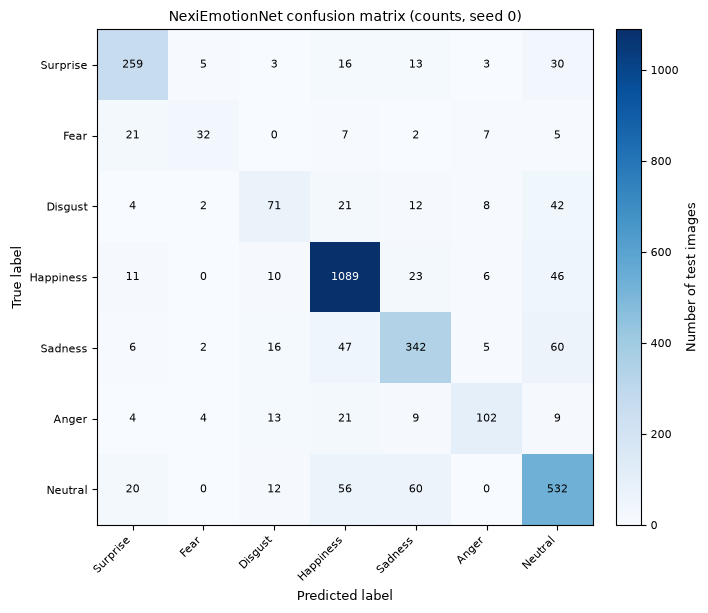

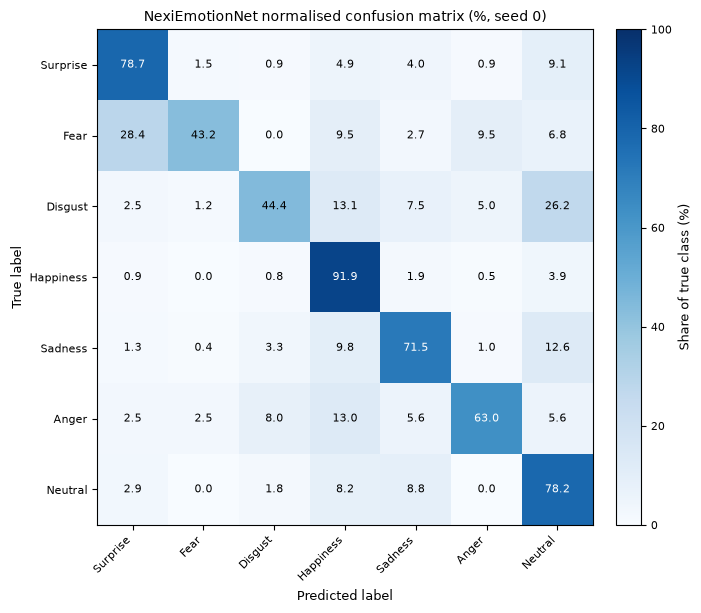

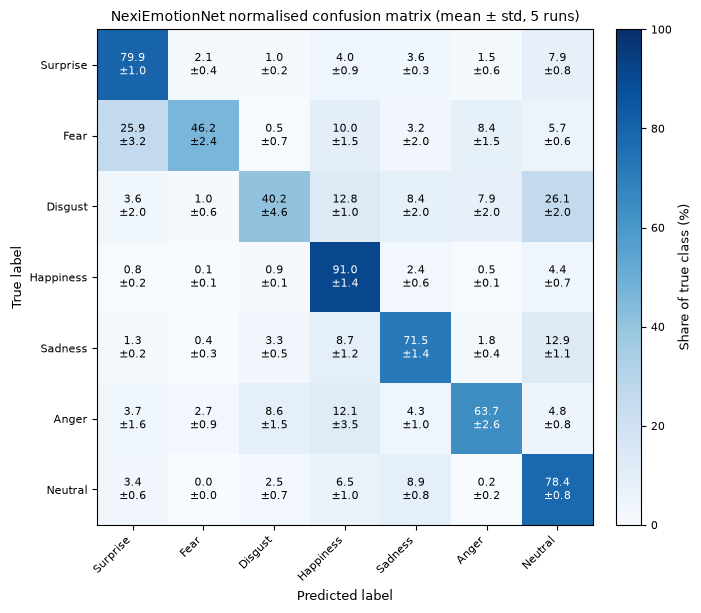

Classification report (seed 0):
              precision    recall  f1-score   support

    Surprise     0.7969    0.7872    0.7920       329
        Fear     0.7111    0.4324    0.5378        74
     Disgust     0.5680    0.4437    0.4982       160
   Happiness     0.8663    0.9190    0.8919      1185
     Sadness     0.7419    0.7155    0.7284       478
       Anger     0.7786    0.6296    0.6962       162
     Neutral     0.7348    0.7824    0.7578       680

    accuracy                         0.7911      3068
   macro avg     0.7425    0.6728    0.7004      3068
weighted avg     0.7864    0.7911    0.7866      3068



In [23]:
# Figure style: 300 dpi export and text no smaller than 8 pt (journal requirement)
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8})


def plot_confusion_matrix(matrix, annotations, title, file_name, cbar_label, vmax=None):
    """Draw an annotated confusion matrix and save it with 300 dpi."""
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(7)); ax.set_yticks(range(7))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(title)
    threshold = (vmax if vmax is not None else matrix.max()) / 2
    for i in range(7):
        for j in range(7):
            ax.text(j, i, annotations[i][j], ha="center", va="center", fontsize=8,
                    color="white" if matrix[i, j] > threshold else "black")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "figures" / file_name, dpi=300, bbox_inches="tight")
    plt.show()


recs = load_runs("d_Full", SEEDS)
if recs:
    # (1) Raw counts and (2) row-normalised matrix for the first seed
    r0 = recs[0]
    cm = confusion_matrix(r0["labels"], r0["preds"], labels=list(range(7)))
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    plot_confusion_matrix(cm, [[str(v) for v in row] for row in cm],
                          f"NexiEmotionNet confusion matrix (counts, seed {r0['seed']})",
                          "confusion_matrix_counts_seed0.png", "Number of test images")
    plot_confusion_matrix(cm_pct, [[f"{v:.1f}" for v in row] for row in cm_pct],
                          f"NexiEmotionNet normalised confusion matrix (%, seed {r0['seed']})",
                          "confusion_matrix_normalized_seed0.png", "Share of true class (%)", vmax=100)

    # (3) Mean ± std of the row-normalised matrices over all finished seeds
    all_pct = np.array([confusion_matrix(r["labels"], r["preds"], labels=list(range(7))) /
                        confusion_matrix(r["labels"], r["preds"], labels=list(range(7))).sum(axis=1, keepdims=True) * 100
                        for r in recs])
    mean_pct = all_pct.mean(axis=0)
    std_pct = all_pct.std(axis=0, ddof=1) if len(recs) > 1 else np.zeros_like(mean_pct)
    plot_confusion_matrix(mean_pct, [[f"{mean_pct[i, j]:.1f}\n±{std_pct[i, j]:.1f}" for j in range(7)] for i in range(7)],
                          f"NexiEmotionNet normalised confusion matrix (mean ± std, {len(recs)} runs)",
                          "confusion_matrix_normalized_mean_std.png", "Share of true class (%)", vmax=100)

    print(f"Classification report (seed {r0['seed']}):")
    print(classification_report(r0["labels"], r0["preds"], target_names=CLASS_NAMES, digits=4))
else:
    print("No finished runs of 'd_Full' yet; run Section 11 first.")

## 18. Summary and Reproducibility

In [24]:
print_section4_text()

print("\n---- Files written to", RESULTS_DIR, "----")
for sub in ["tables", "figures"]:
    for p in sorted((RESULTS_DIR / sub).glob("*")):
        print(f"  {sub}/{p.name}")
print("  environment.json, emotion_model.pt, runs/*.json (per-run results), checkpoints/*.pt")

# Optional: bundle all results into one zip file for download
archive = shutil.make_archive(str(BASE_DIR / "NexiEmotionNet_results_bundle"), "zip", RESULTS_DIR)
print("\nResults bundle created:", archive)

---- Experimental setup (all values are taken from this notebook) ----

Hardware and software: Experiments were run on NVIDIA GeForce RTX 5060 (x1, 8.5 GB), Intel64 Family 6 Model 151 Stepping 5, GenuineIntel (12 vCPUs), None GB RAM, Windows-10-10.0.19045-SP0. Software: Python 3.13.7, PyTorch 2.11.0+cu128, torchvision 0.26.0+cu128, CUDA 12.8, cuDNN 91900. Computation used FP32 (TF32 disabled: True) with deterministic cuDNN kernels.

Preprocessing and augmentation: Images are resized to 224x224 (bilinear interpolation, torchvision default). Training images are augmented with RandomHorizontalFlip (p=0.5), RandomRotation (+/-10 degrees) and ColorJitter (brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2), then normalised per channel with x' = (x - 0.5) / 0.5. Test images are only resized and normalised.

Optimisation: AdamW (lr=0.001, weight decay=0.01, betas=(0.9, 0.999)), batch size 64, 30 epochs, Focal loss (gamma=2.0, alpha=0.25), dropout 0.4 after global average pooling.

Learning